Extracted fake_job_postings.csv from: data\archive.zip
Dataset shape: (17880, 18)

Class distribution:
Real (0): 17014 | Fraud (1): 866 (4.84% fraud)

Missing values (%) per column:


,Missing %
salary_range,83.96
department,64.58
required_education,45.33
benefits,40.34
required_experience,39.43
function,36.10
industry,27.42
employment_type,19.41
company_profile,18.50
requirements,15.08



Fraud rate (%) by has_company_logo:


,Fraud Rate %
has_company_logo,
0,15.93
1,1.99



Fraud rate (%) by employment_type:


,Fraud Rate %
employment_type,
Contract,2.89
Full-time,4.22
Missing,6.94
Other,6.61
Part-time,9.28
Temporary,0.83



Text character length summary by class:


,mean,median,std
fraudulent,,,
0,2700.6,2560.5,1455.8
1,2078.6,1656.5,1529.7


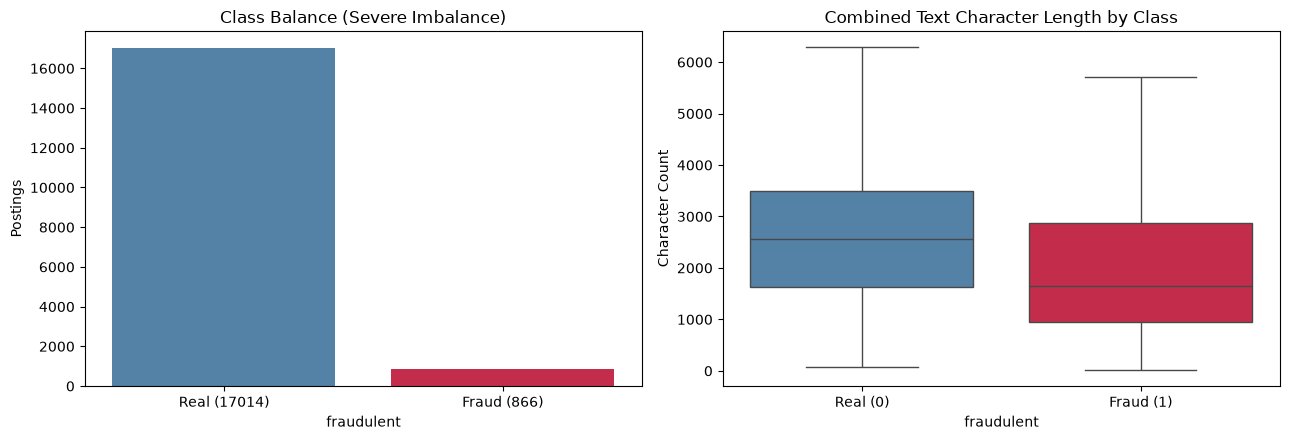

In [2]:
import os
import re
import glob
import shutil
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

target_csv = os.path.join("data", "fake_job_postings.csv")

# Search data/, current folder, Downloads, and Desktop for the CSV or ZIP file
search_dirs = ["data", ".", "..", os.path.expanduser("~/Downloads"), os.path.expanduser("~/Desktop")]

if not os.path.exists(target_csv):
    for folder in search_dirs:
        csv_hits = glob.glob(os.path.join(folder, "fake_job_postings.csv")) + glob.glob(os.path.join(folder, "*", "fake_job_postings.csv"))
        if csv_hits:
            shutil.copy2(csv_hits[0], target_csv)
            print(f"Copied CSV from: {csv_hits[0]}")
            break

if not os.path.exists(target_csv):
    for folder in search_dirs:
        for zpath in sorted(glob.glob(os.path.join(folder, "*.zip")), key=os.path.getmtime, reverse=True):
            try:
                with zipfile.ZipFile(zpath, "r") as zf:
                    matches = [m for m in zf.namelist() if m.endswith("fake_job_postings.csv")]
                    if matches:
                        with zf.open(matches[0]) as src, open(target_csv, "wb") as dst:
                            shutil.copyfileobj(src, dst)
                        print(f"Extracted fake_job_postings.csv from: {zpath}")
                        break
            except Exception:
                pass
        if os.path.exists(target_csv):
            break

if not os.path.exists(target_csv):
    raise FileNotFoundError("Could not find fake_job_postings.csv or its ZIP archive in data/ or Downloads.")

# Load dataset
df = pd.read_csv(target_csv)
print(f"Dataset shape: {df.shape}")

# 1. Class balance
counts = df["fraudulent"].value_counts()
fraud_pct = df["fraudulent"].mean() * 100
print(f"\nClass distribution:\nReal (0): {counts[0]} | Fraud (1): {counts[1]} ({fraud_pct:.2f}% fraud)")

# 2. Missing value percentage per column
missing_pct = (df.isnull().mean() * 100).round(2).sort_values(ascending=False)
print("\nMissing values (%) per column:")
display(missing_pct[missing_pct > 0].to_frame("Missing %"))

# 3. Fraud rate by has_company_logo and employment_type
print("\nFraud rate (%) by has_company_logo:")
display((df.groupby("has_company_logo")["fraudulent"].mean() * 100).round(2).to_frame("Fraud Rate %"))

print("\nFraud rate (%) by employment_type:")
display((df.fillna({"employment_type": "Missing"}).groupby("employment_type")["fraudulent"].mean() * 100).round(2).to_frame("Fraud Rate %"))

# 4. Text length distribution per class
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
raw_text = df[text_cols].fillna("").agg(" ".join, axis=1)
df["text_char_len"] = raw_text.str.len()

print("\nText character length summary by class:")
display(df.groupby("fraudulent")["text_char_len"].agg(["mean", "median", "std"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x="fraudulent", hue="fraudulent", data=df, ax=axes[0], palette=["steelblue", "crimson"], legend=False)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels([f"Real ({counts[0]})", f"Fraud ({counts[1]})"])
axes[0].set_title("Class Balance (Severe Imbalance)")
axes[0].set_ylabel("Postings")

sns.boxplot(x="fraudulent", y="text_char_len", hue="fraudulent", data=df, ax=axes[1], palette=["steelblue", "crimson"], showfliers=False, legend=False)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Real (0)", "Fraud (1)"])
axes[1].set_title("Combined Text Character Length by Class")
axes[1].set_ylabel("Character Count")

plt.tight_layout()
plt.savefig("figures/b1_eda.png", dpi=300)
plt.show()